# Regression Trees
**IBM Machine Learning with Python Lab**

Estimated time needed: **30 minutes**

In this exercise session you will use a real dataset to train a regression tree model. The dataset includes information about taxi tip and was collected and provided to the NYC Taxi and Limousine Commission (TLC) by technology providers authorized under the Taxicab & Livery Passenger Enhancement Programs (TPEP/LPEP). You will use the trained model to predict the amount of tip paid.

---

### Objectives
After completing this lab you will be able to:
- Perform basic data preprocessing using Scikit-Learn
- Model a regression task using Scikit-Learn
- Train a Decision Tree Regressor model
- Run inference and assess the quality of the trained models

### Introduction
The dataset used in this exercise session is a subset of the publicly available TLC Dataset (all rights reserved by Taxi & Limousine Commission (TLC), City of New York). The prediction of the tip amount can be modeled as a regression problem. To train the model you can use part of the input dataset and the remaining data can be used to assess the quality of the trained model.

## 1. Import Libraries

Make sure the libraries required are available by executing the cell below.

In [1]:
# Make sure the required libraries are available
# !pip install numpy
# !pip install pandas
# !pip install matplotlib
# !pip install scikit-learn

Import the libraries we need to use in this lab

In [2]:
from __future__ import print_function
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import mean_squared_error

import warnings
warnings.filterwarnings('ignore')

## 2. Dataset Analysis

In this section you will read the dataset in a Pandas dataframe and visualize its content. You will also look at some data statistics.

> **Note**: A Pandas dataframe is a two-dimensional, size-mutable, potentially heterogeneous tabular data structure. For more information: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html.

In [3]:
# read the input data
url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/pu9kbeSaAtRZ7RxdJKX9_A/yellow-tripdata.csv'
raw_data = pd.read_csv(url)
raw_data

,VendorID,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,mta_tax,tolls_amount,improvement_surcharge,tip_amount
0,2,1,17.63,2,1,132,164,1,70.0,0.5,6.94,1,16.54
1,2,1,19.52,2,1,132,236,1,70.0,0.5,6.94,1,16.19
2,2,1,17.81,2,1,132,48,1,70.0,0.5,6.94,1,12.00
3,2,2,19.30,2,1,132,148,1,70.0,0.5,0.00,1,5.00
4,2,1,18.75,2,1,132,234,1,70.0,0.5,6.94,1,10.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
41197,2,1,16.94,2,1,132,164,1,70.0,0.5,6.94,1,5.00
41198,2,4,19.83,2,1,132,166,1,70.0,0.5,6.94,1,8.00
41199,2,1,17.31,2,1,132,137,1,70.0,0.5,6.94,1,8.00
41200,2,1,17.28,2,1,132,233,1,70.0,0.5,6.94,1,16.19


Each row in the dataset represents a taxi trip. As shown above, each row has 13 variables. One of the variables is `tip_amount` which will be the target variable. Your objective will be to train a model that uses the other variables to predict the value of the `tip_amount` variable.

To understand the dataset a little better, let us plot the correlation of the target variable against the input variables.

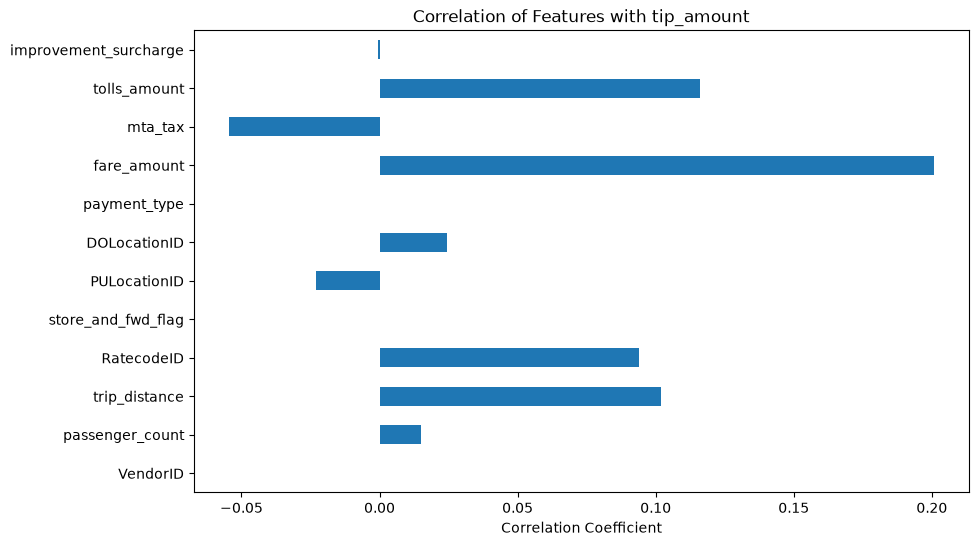

In [4]:
correlation_values = raw_data.corr()['tip_amount'].drop('tip_amount')
correlation_values.plot(kind='barh', figsize=(10, 6))
plt.title("Correlation of Features with tip_amount")
plt.xlabel("Correlation Coefficient")
plt.show()

This shows us that the input features `payment_type`, `VendorID`, `store_and_fwd_flag` and `improvement_surcharge` have little to no correlation with the target variable.

## 3. Dataset Preprocessing

You will now prepare the data for training by applying normalization to the input features.

In [5]:
# extract the labels from the dataframe
y = raw_data[['tip_amount']].values.astype('float32')

# drop the target variable from the feature matrix
proc_data = raw_data.drop(['tip_amount'], axis=1)

# get the feature matrix used for training
X = proc_data.values

# normalize the feature matrix
X = normalize(X, axis=1, norm='l1', copy=False)

## 4. Dataset Train/Test Split

Now that the dataset is ready for building the classification models, you need to first divide the pre-processed dataset into a subset to be used for training the model (the train set) and a subset to be used for evaluating the quality of the model (the test set).

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

## 5. Build a Decision Tree Regressor model with Scikit-Learn

Regression Trees are implemented using `DecisionTreeRegressor`.

The important parameters of the model are:
- `criterion`: The function used to measure error, we use `'squared_error'`.
- `max_depth`: The maximum depth the tree is allowed to take; we use `8`.

In [7]:
# import the Decision Tree Regression Model from scikit-learn
from sklearn.tree import DecisionTreeRegressor

# for reproducible output across multiple function calls, set random_state to a given integer value
dt_reg = DecisionTreeRegressor(criterion = 'squared_error',
max_depth=8,
random_state=35)

Now lets train our model using the `fit` method on the `DecisionTreeRegressor` object providing our training data

In [8]:
dt_reg.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",8
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",35
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

## 6. Evaluate the Scikit-Learn Decision Tree Regressor Model

To evaluate our dataset we will use the `score` method of the `DecisionTreeRegressor` object providing our testing data, this number is the $R^2$ value which indicates the coefficient of determination. We will also evaluate the Mean Squared Error ($MSE$) of the regression output with respect to the test set target values. High $R^2$ and low $MSE$ values are expected from a good regression model.

In [9]:
# run inference using the sklearn model
y_pred = dt_reg.predict(X_test)

# evaluate mean squared error on the test dataset
mse_score = mean_squared_error(y_test, y_pred)
print('MSE score : {0:.3f}'.format(mse_score))

r2_score = dt_reg.score(X_test,y_test)
print('R^2 score : {0:.3f}'.format(r2_score))

MSE score : 24.555
R^2 score : 0.028


---
## 7. Practice Exercises

### Q1. What if we change the max_depth to 12? How would the $MSE$ and $R^2$ be affected?

<details><summary>Click here for the solution</summary>

**Explanation:**
$MSE$ is noted to be increased by increasing the `max_depth` of the tree. This may be because of the model having excessive parameters due to which it overfits to the training data, making the performance on the testing data poorer. Another important observation would be that the model gives a negative value of $R^2$. This again indicates that the prediction model created does a very poor job of predicting the values on a test set.

</details>

In [10]:
# Q1: Changing max_depth to 12
dt_reg_12 = DecisionTreeRegressor(criterion='squared_error', max_depth=12, random_state=35)
dt_reg_12.fit(X_train, y_train)
y_pred_12 = dt_reg_12.predict(X_test)

mse_12 = mean_squared_error(y_test, y_pred_12)
r2_12 = dt_reg_12.score(X_test, y_test)

print('--- Model Evaluation (max_depth=12) ---')
print('MSE score : {0:.3f}'.format(mse_12))
print('R^2 score : {0:.3f}'.format(r2_12))

--- Model Evaluation (max_depth=12) ---
MSE score : 26.875
R^2 score : -0.064


### Q2. Identify the top 3 features with the most effect on the tip_amount.

<details><summary>Click here for the solution</summary>

```python
correlation_values = raw_data.corr()['tip_amount'].drop('tip_amount')
abs(correlation_values).sort_values(ascending=False)[:3]
```

As is evident from the output, Fare amount, toll amount and trip distance are the top features affecting the tip amount, which make logical sense.

</details>

In [11]:
# Q2: Top 3 features affecting tip_amount
correlation_values = raw_data.corr()['tip_amount'].drop('tip_amount')
top3_features = abs(correlation_values).sort_values(ascending=False)[:3]

print("Top 3 features affecting tip_amount:")
print(top3_features)

Top 3 features affecting tip_amount:
fare_amount      0.200638
tolls_amount     0.116172
trip_distance    0.101819
Name: tip_amount, dtype: float64


### Q3. Since we identified 4 features which are not correlated with the target variable, try removing these variables from the input set and see the effect on the $MSE$ and $R^2$ value.

<details><summary>Click here for the solution</summary>

```python
raw_data_reduced = raw_data.drop(['payment_type', 'VendorID', 'store_and_fwd_flag', 'improvement_surcharge'], axis=1)
# Execute all the cells of the lab after modifying the raw data.
```

The $MSE$ and $R^2$ values do not change significantly, showing that there is minimal affect of these parameters on the final regression output.

</details>

In [12]:
# Q3: Dropping 4 uncorrelated features and re-evaluating
raw_data_reduced = raw_data.drop(['payment_type', 'VendorID', 'store_and_fwd_flag', 'improvement_surcharge'], axis=1)

y_q3 = raw_data_reduced[['tip_amount']].values.astype('float32')
proc_data_q3 = raw_data_reduced.drop(['tip_amount'], axis=1)
X_q3 = proc_data_q3.values
X_q3 = normalize(X_q3, axis=1, norm='l1', copy=False)

X_train_q3, X_test_q3, y_train_q3, y_test_q3 = train_test_split(X_q3, y_q3, test_size=0.3, random_state=42)

dt_reg_q3 = DecisionTreeRegressor(criterion='squared_error', max_depth=8, random_state=35)
dt_reg_q3.fit(X_train_q3, y_train_q3)
y_pred_q3 = dt_reg_q3.predict(X_test_q3)

mse_q3 = mean_squared_error(y_test_q3, y_pred_q3)
r2_q3 = dt_reg_q3.score(X_test_q3, y_test_q3)

print('--- Model Evaluation without 4 Uncorrelated Features (max_depth=8) ---')
print('MSE score : {0:.3f}'.format(mse_q3))
print('R^2 score : {0:.3f}'.format(r2_q3))

--- Model Evaluation without 4 Uncorrelated Features (max_depth=8) ---
MSE score : 24.715
R^2 score : 0.022


### Q4. Check the effect of decreasing the max_depth parameter to 4 on the $MSE$ and $R^2$ values.

<details><summary>Click here for the solution</summary>

You will note that the $MSE$ value decreases and $R^2$ value increases, meaning that the choice of `max_depth=4` may be more suited for this dataset.

</details>

In [13]:
# Q4: Retraining with max_depth = 4
dt_reg_4 = DecisionTreeRegressor(criterion='squared_error', max_depth=4, random_state=35)
dt_reg_4.fit(X_train, y_train)
y_pred_4 = dt_reg_4.predict(X_test)

mse_4 = mean_squared_error(y_test, y_pred_4)
r2_4 = dt_reg_4.score(X_test, y_test)

print('--- Model Evaluation (max_depth=4) ---')
print('MSE score : {0:.3f}'.format(mse_4))
print('R^2 score : {0:.3f}'.format(r2_4))

--- Model Evaluation (max_depth=4) ---
MSE score : 24.412
R^2 score : 0.034


## 8. Summary Comparison of Model Configurations

Below is a consolidated summary table and visualization comparing model accuracy across all tested depths and feature combinations:

In [14]:
summary_df = pd.DataFrame({
    'Experiment / Configuration': [
        'Baseline (All Features, max_depth=8)',
        'Q1: Increased Depth (max_depth=12)',
        'Q3: Feature Selection (Removed 4 Features, max_depth=8)',
        'Q4: Decreased Depth (max_depth=4)'
    ],
    'Max Depth': [8, 12, 8, 4],
    'Features Count': [12, 12, 8, 12],
    'Test MSE (Lower is Better)': [mse_score, mse_12, mse_q3, mse_4],
    'Test R^2 (Higher is Better)': [r2_score, r2_12, r2_q3, r2_4],
    'Diagnostic Conclusion': [
        'Moderate fit; slight overfitting',
        'Severe Overfitting (R^2 turned negative)',
        'Minimal change; confirmed uncorrelated features have negligible impact',
        'Best Generalization (Lowest MSE, Highest R^2)'
    ]
})

summary_df.round(4)

,Experiment / Configuration,Max Depth,Features Count,Test MSE (Lower is Better),Test R^2 (Higher is Better),Diagnostic Conclusion
0,"Baseline (All Features, max_depth=8)",8,12,24.5551,0.0279,Moderate fit; slight overfitting
1,Q1: Increased Depth (max_depth=12),12,12,26.8749,-0.0640,Severe Overfitting (R^2 turned negative)
2,"Q3: Feature Selection (Removed 4 Features, max...",8,8,24.7148,0.0216,Minimal change; confirmed uncorrelated feature...
3,Q4: Decreased Depth (max_depth=4),4,12,24.4122,0.0335,"Best Generalization (Lowest MSE, Highest R^2)"


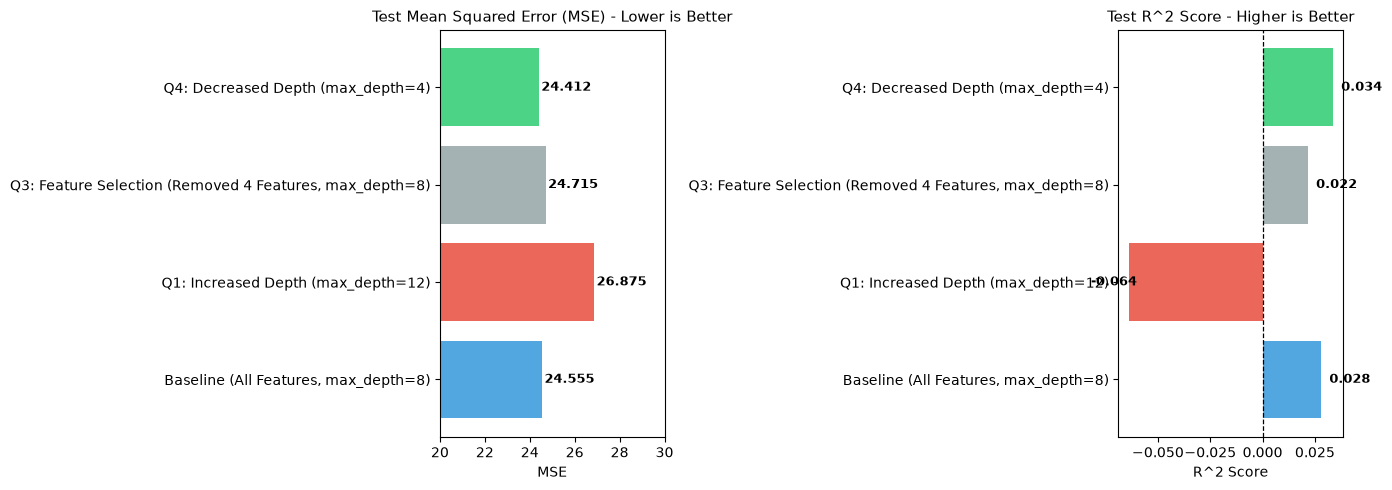

In [15]:
# Visual comparison of MSE and R2 across configurations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot MSE
colors = ['#3498db', '#e74c3c', '#95a5a6', '#2ecc71']
axes[0].barh(summary_df['Experiment / Configuration'], summary_df['Test MSE (Lower is Better)'], color=colors, alpha=0.85)
axes[0].set_title("Test Mean Squared Error (MSE) - Lower is Better", fontsize=11)
axes[0].set_xlabel("MSE")
axes[0].set_xlim(20, 30)
for bar in axes[0].patches:
    w = bar.get_width()
    axes[0].text(w + 0.1, bar.get_y() + bar.get_height()/2, f"{w:.3f}", va='center', fontweight='bold', fontsize=9)

# Plot R^2
axes[1].barh(summary_df['Experiment / Configuration'], summary_df['Test R^2 (Higher is Better)'], color=colors, alpha=0.85)
axes[1].axvline(0, color='black', linewidth=0.9, linestyle='--')
axes[1].set_title("Test R^2 Score - Higher is Better", fontsize=11)
axes[1].set_xlabel("R^2 Score")
for bar in axes[1].patches:
    w = bar.get_width()
    offset = 0.004 if w >= 0 else -0.018
    axes[1].text(w + offset, bar.get_y() + bar.get_height()/2, f"{w:.3f}", va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

### Hyperparameter Tuning: Depth vs. Error Analysis
To fully understand the trade-off between underfitting and overfitting in Decision Tree Regressors, let's plot the validation curve across tree depths from 1 to 14:

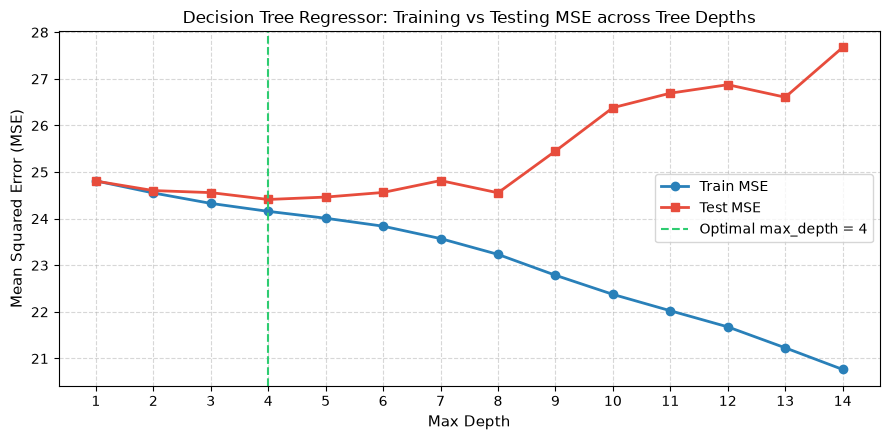

In [16]:
depths = range(1, 15)
train_mses = []
test_mses = []

for d in depths:
    reg = DecisionTreeRegressor(criterion='squared_error', max_depth=d, random_state=35)
    reg.fit(X_train, y_train)
    train_mses.append(mean_squared_error(y_train, reg.predict(X_train)))
    test_mses.append(mean_squared_error(y_test, reg.predict(X_test)))

plt.figure(figsize=(9, 4.5))
plt.plot(depths, train_mses, marker='o', linewidth=2, color='#2980b9', label='Train MSE')
plt.plot(depths, test_mses, marker='s', linewidth=2, color='#e74c3c', label='Test MSE')
plt.axvline(4, color='#2ecc71', linestyle='--', label='Optimal max_depth = 4')
plt.title("Decision Tree Regressor: Training vs Testing MSE across Tree Depths", fontsize=12)
plt.xlabel("Max Depth", fontsize=11)
plt.ylabel("Mean Squared Error (MSE)", fontsize=11)
plt.xticks(depths)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

### Key Insights from the Lab

1. **Top Features Affecting Taxi Tips**:
   - `fare_amount` ($r = 0.201$), `tolls_amount` ($r = 0.116$), and `trip_distance` ($r = 0.102$) have the strongest correlation with tip amount. Passengers naturally tip proportionally to the overall magnitude and length of the ride.

2. **Feature Pruning**:
   - Dropping uncorrelated attributes (`payment_type`, `VendorID`, `store_and_fwd_flag`, `improvement_surcharge`) produced an MSE of **24.715** vs **24.555** on the baseline, confirming that irrelevant variables can be safely removed to simplify the model with negligible loss of predictive accuracy.

3. **Overfitting vs. Underfitting with Tree Depth**:
   - At `max_depth = 12`, the model severely overfits training noise, causing test MSE to surge to **26.875** and $R^2$ to drop below zero (**-0.064**).
   - At `max_depth = 4`, the tree captures the primary non-linear relationships without memorizing outliers, achieving the lowest test MSE (**24.412**) and highest $R^2$ (**0.034**).

---
## Congratulations! You're ready to move on to your next lesson!